In [2]:
import json
from collections import defaultdict
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [3]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (12, 5),
         'axes.labelsize': 'large',
         'axes.titlesize':'large',
         'xtick.labelsize':'medium',
         'ytick.labelsize':'medium',
         'font.family':'serif'}
pylab.rcParams.update(params)

In [4]:
# 1. Load the NDJSON file into a DataFrame
# 'lines=True' tells pandas to treat each line as a separate JSON object
#df = pd.read_json('/Users/Katie/Documents/MagAO-X/Data/ADC/2026A/logs_2dof_reformatted_copy.ndjson', lines=True)
df = pd.read_json('/Users/Katie/Documents/MagAO-X/Data/ADC/2026A/log_orientation2.ndjson', lines=True)

# 2. Expand the nested 'coi' lists into individual columns
# The 'coi' column currently looks like: [[x1, y1], [x2, y2], [x3, y3], [x4, y4], [x5, y5]]
coi_expanded = pd.DataFrame(df['coi'].tolist(), columns=[f'coi_{i+1}' for i in range(5)])

# # 3. Create separate X and Y columns for each of the 5 COI points
for i in range(5):
    col_name = f'coi_{i+1}'
    df[[f'{col_name}_x', f'{col_name}_y']] = pd.DataFrame(coi_expanded[col_name].tolist(), index=df.index)

# 4. Remove the original nested 'coi' column
df_final = df.drop(columns=['coi'])

# 5. Display the result
print(df_final.head())   

   iteration                                vec  shear_control_iter  \
0          1  [-2.7099165100000002, 4.52456212]           -1.000000   
1          2          [-2.26900486, 2.36889151]           -0.682269   
2          3          [-2.18881036, 1.15457071]           -0.332530   
3          4          [-1.95244387, 0.31724461]           -0.091370   
4          5          [-1.68502075, 0.38907187]           -0.112057   

   total_shear_control  co_rotation_control_iter  total_co_rotation_control  \
0             2.000000                       1.0                        1.0   
1             1.317731                       1.0                        2.0   
2             0.985202                       1.0                        3.0   
3             0.893831                       NaN                        4.0   
4             0.781774                       1.0                        5.0   

   co_rotation_control a_iter   coi_1_x   coi_1_y   coi_2_x   coi_2_y  \
0                        

In [5]:
df_final.keys()

Index(['iteration', 'vec', 'shear_control_iter', 'total_shear_control',
       'co_rotation_control_iter', 'total_co_rotation_control',
       'co_rotation_control a_iter', 'coi_1_x', 'coi_1_y', 'coi_2_x',
       'coi_2_y', 'coi_3_x', 'coi_3_y', 'coi_4_x', 'coi_4_y', 'coi_5_x',
       'coi_5_y'],
      dtype='object')

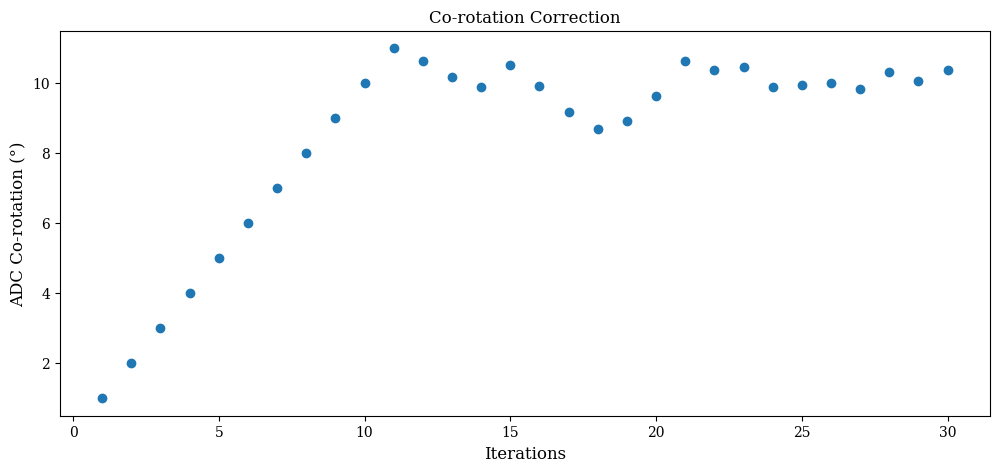

In [6]:
iteration = df_final['iteration']
corotation_total = df_final['total_co_rotation_control']
plt.scatter(iteration,corotation_total)
plt.title('Co-rotation Correction')
plt.xlabel('Iterations')
plt.ylabel('ADC Co-rotation (°)')
plt.show()

convergence point: 10.266444868224033


/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_2813/2810334763.py:2: RuntimeWarning: overflow encountered in exp
  y = a * np.exp(-b*x) + c


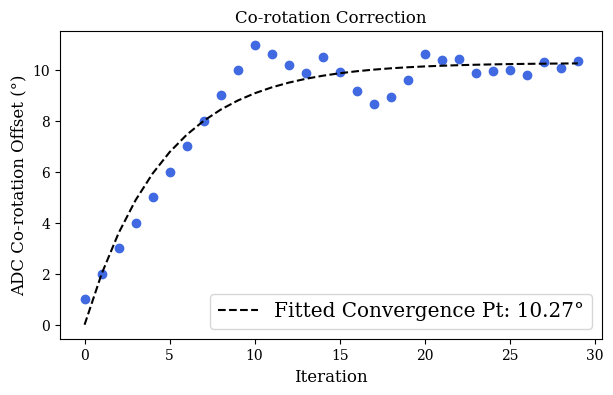

In [7]:
def test_exp(x,a,b,c):
    y = a * np.exp(-b*x) + c
    return y

x = np.arange(30)
params, cov = curve_fit(test_exp,x,corotation_total)
print(f'convergence point: {params[2]}')

fitted = test_exp(x,*params)
fig = plt.figure(figsize=(7,4))
plt.plot(fitted,'--',color='black',label=f'Fitted Convergence Pt: {params[2]:.2f}°')
plt.scatter(x,corotation_total,color='royalblue')
plt.title('Co-rotation Correction')
plt.xlabel('Iteration')
plt.ylabel('ADC Co-rotation Offset (°)')
plt.legend()
plt.show()

In [8]:
fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/alphcir_corotation.png')

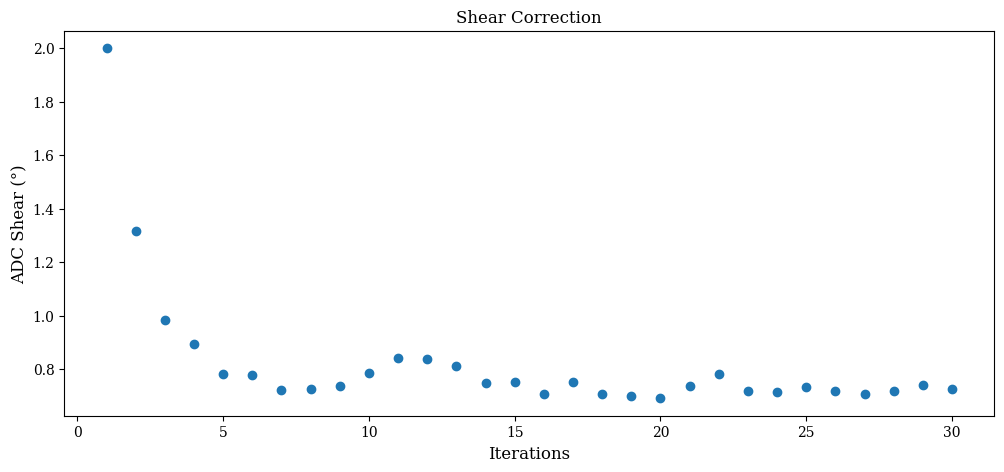

In [9]:
iteration = df_final['iteration']
shear_total = df_final['total_shear_control']
plt.scatter(iteration,shear_total)
plt.title('Shear Correction')
plt.xlabel('Iterations')
plt.ylabel('ADC Shear (°)')
plt.show()

In [10]:
shear_total[2]

np.float64(0.9852015047836041)

In [11]:
dxdy = df_final['vec'].values.tolist()
dxdy = np.array(dxdy) * 764/656
dx = dxdy[:,0]
dy = dxdy[:,1]
print(dx)
print(dy)

[-3.1560613  -2.64256054 -2.54916329 -2.2738828  -1.9624327  -1.477047
 -1.25295891 -0.8592669  -0.52011982 -0.51683375 -0.37834687  0.13883423
  0.17536926  0.11311692 -0.24311161  0.22966637  0.28854639  0.18955978
 -0.09435599 -0.26818374 -0.41536509  0.09621151 -0.02673539  0.2146929
 -0.0234037  -0.02159373  0.06997398 -0.18808178  0.09427701 -0.11416917]
[ 5.26945954  2.75889194  1.34465247  0.36947391  0.45312639  0.01909436
  0.21355046 -0.01115456 -0.05010406 -0.18372494 -0.23336446  0.01135851
  0.10763227  0.26518423 -0.01684012  0.17847671 -0.18784297  0.19185333
  0.02041565  0.03814011 -0.19168241 -0.16880318  0.25669578  0.01396628
 -0.0801759   0.05625299  0.05700091 -0.05465587 -0.09093121  0.06719587]


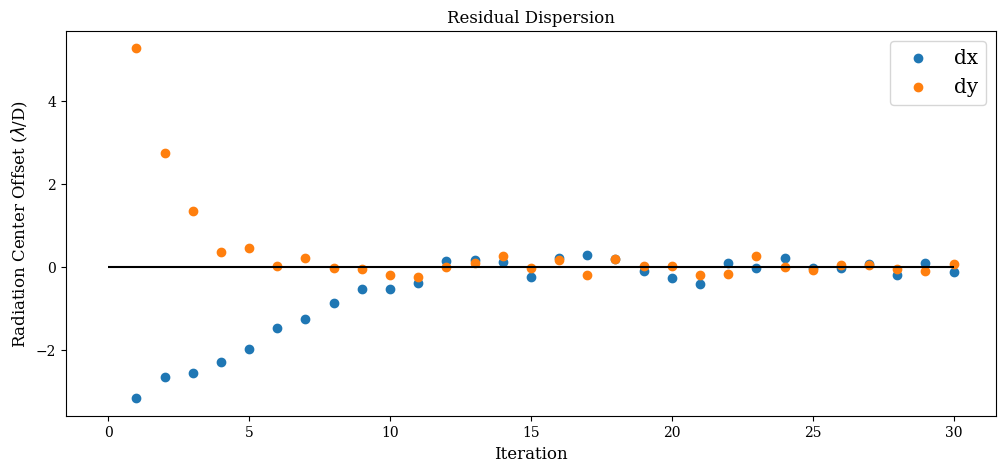

In [12]:
plt.scatter(iteration,dx,label='dx')
plt.scatter(iteration,dy,label='dy')
plt.title('Residual Dispersion')
plt.xlabel('Iteration')
plt.ylabel(r'Radiation Center Offset ($\lambda$/D)')
plt.hlines(0,0,30,color='black')
plt.legend()
plt.show()

In [13]:
#convert the residual dispersion into real units


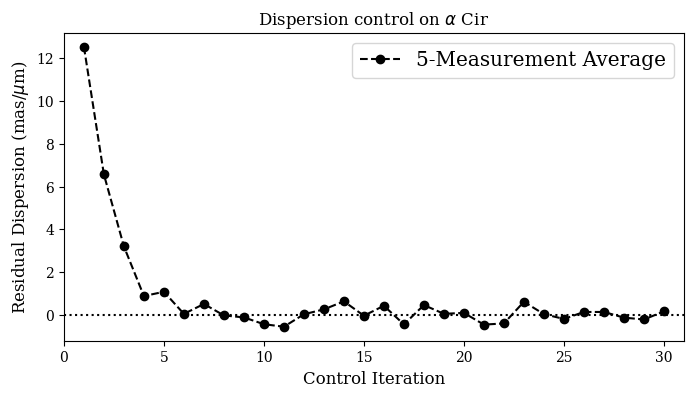

In [23]:
dy_dispersion = dy * 2.38 #mas/um PER lam/D

fig = plt.figure(figsize=(8,4))
plt.plot(iteration,dy_dispersion,'o--',label='5-Measurement Average',color='black')
plt.title(r'Dispersion control on $\alpha$ Cir')
plt.xlabel('Control Iteration')
plt.xlim((0,31))
plt.ylabel(r'Residual Dispersion (mas/$\mu$m)')
plt.hlines(0,0,31,color='black',linestyles='dotted')
plt.legend()
plt.show()

In [28]:
print(dy_dispersion[7])

-0.02654786005609756


In [ ]:
steadystate = dy_dispersion[7:]
print(np.mean(np.abs(steadystate)))
print(np.std(np.abs(steadystate)))

0.262157241678526
0.32878128287377756


In [24]:
fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/alphcir_convergence.png',dpi=300)